# Bedroom Humidity Forecasting


***

#### Notebook Overview


#### Data Overview

***
#### Key Findings

#### Next Steps

## Imports

In [1]:
# preprocessing
from utils import DataCleanPipleLine

# funcs
from utils.useful_funcs import season_decomp

# viz
import matplotlib.pyplot as plt
import seaborn as sns
from utils import plotting as plot

# files
import os

# time series eda

# ACF / PACF (numeric values and plots)
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Decomposition
from statsmodels.tsa.seasonal import seasonal_decompose, STL

# Stationarity tests
from statsmodels.tsa.stattools import adfuller, kpss

# models

# ARIMA / SARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX   # SARIMA = SARIMAX without exog

# Gradient boosting
from xgboost import XGBRegressor

# Random forest and linear regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

## Data Import

In [2]:

# import data
file_location = os.getenv("F_LOC")

# run data load
cleaning_pipeline = DataCleanPipleLine
pipe_obj = cleaning_pipeline.DataImportAndCleaningPipeline(file_location)

# run pipeline
window_df = pipe_obj.RunPipeline(impute_missing_data=True)



****************************************************************************************************
DF Shape: (256518, 4)
****************************************************************************************************
****************************************************************************************************
                   DateTime  Temperature (oC)    Pressure   Humidity
256517  2026-11-16 12:59:23             14.60  988.647080  66.001950
256518  2026-11-16 13:00:23             14.59  988.658736  66.034180
256519  2026-11-16 13:01:23             14.59  988.651264  66.021484
256520  2026-11-16 13:02:23             14.60  988.647080  66.024416
256521  2026-11-16 13:03:23             14.60  988.666240  65.978516
256522  2026-11-16 13:04:24             14.60  988.666240  65.945310
256523  2026-11-16 13:05:24             14.60  988.613000  65.734376
256524  2026-11-16 13:06:24             14.62  988.616320  65.737308
256525  2026-11-16 13:07:24             14.61  988.635

## Time Series Forecasting: Pre-Modelling Analysis

* Distributions
* Trend and seasonality
* Stationarity
* Autocorrelation

In [3]:
window_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 333615 entries, 2026-03-29 20:54:00+00:00 to 2026-11-16 13:08:00+00:00
Freq: min
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   Temperature (oC)     333615 non-null  float64            
 1   Pressure             333615 non-null  float64            
 2   Humidity             333615 non-null  float64            
 3   DateTime             256500 non-null  datetime64[us, UTC]
 4   Sensor_Status        333615 non-null  str                
 5   Date                 333615 non-null  datetime64[s]      
 6   YearMonth            333615 non-null  period[M]          
 7   EndOfWeek            333615 non-null  datetime64[s]      
 8   Time                 333615 non-null  object             
 9   Time_Numeric         333615 non-null  timedelta64[us]    
 10  DailyAvgTemperature  333615 non-null  float64            
 11  DailyAvgHumidity    

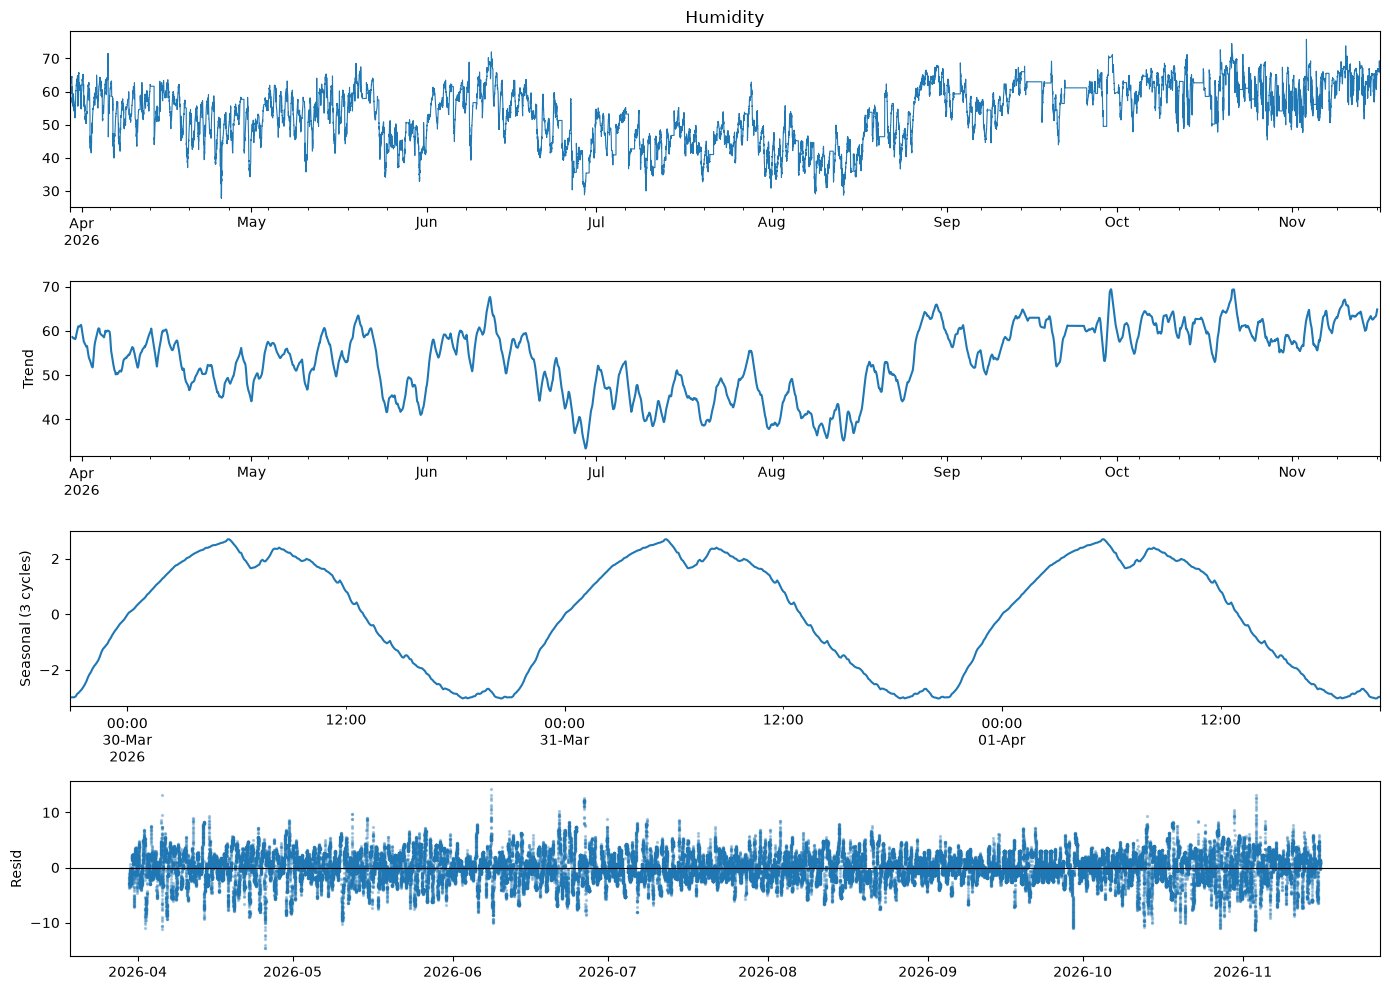

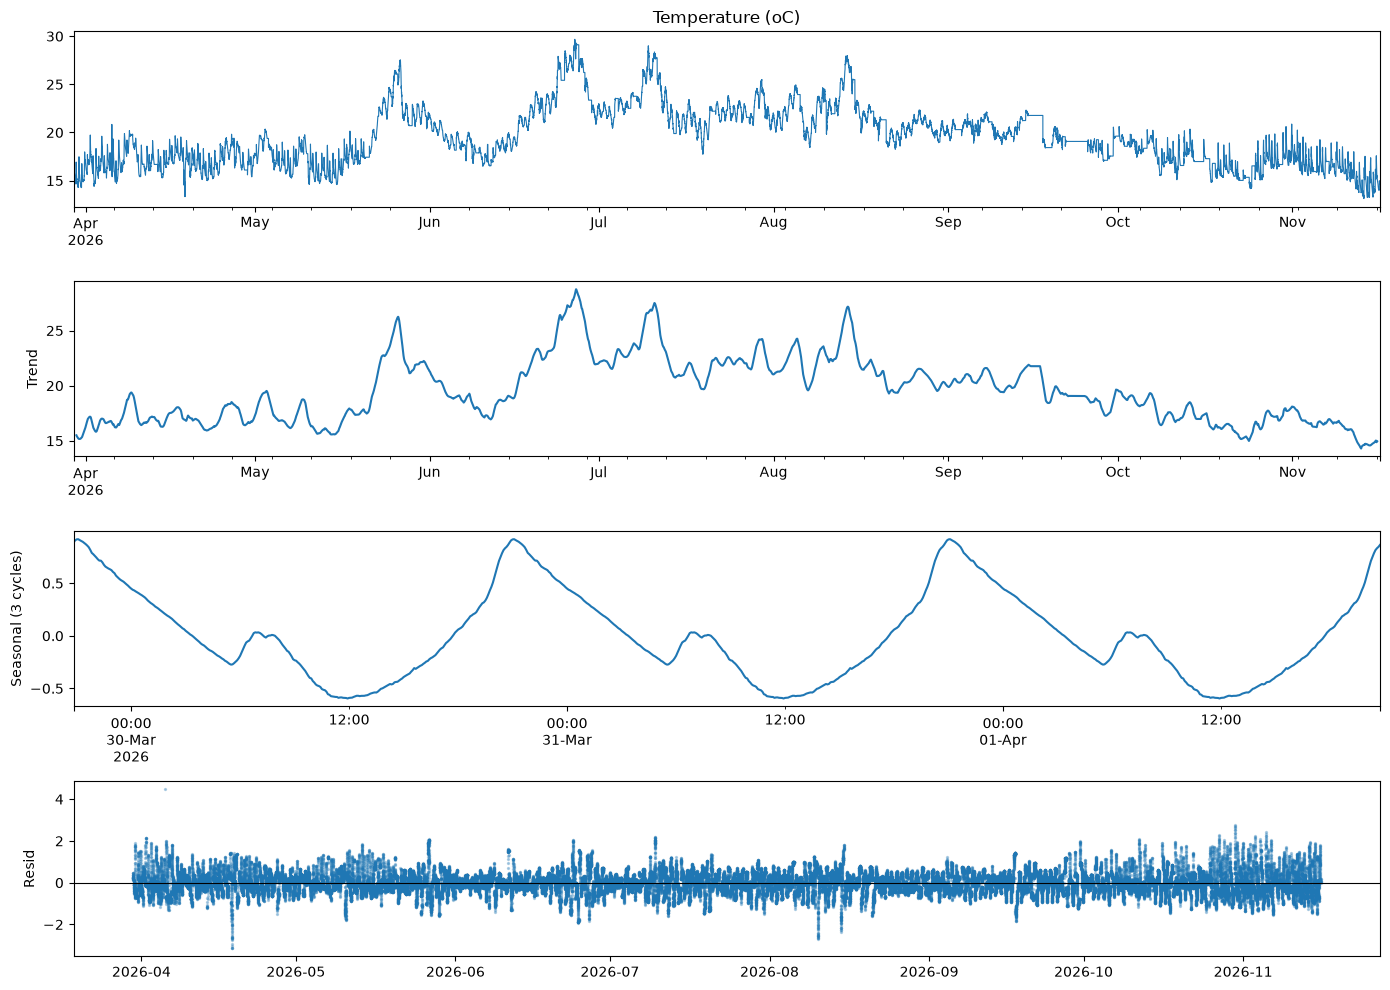

In [4]:
season_decomp(df=window_df,resample_size="5min")


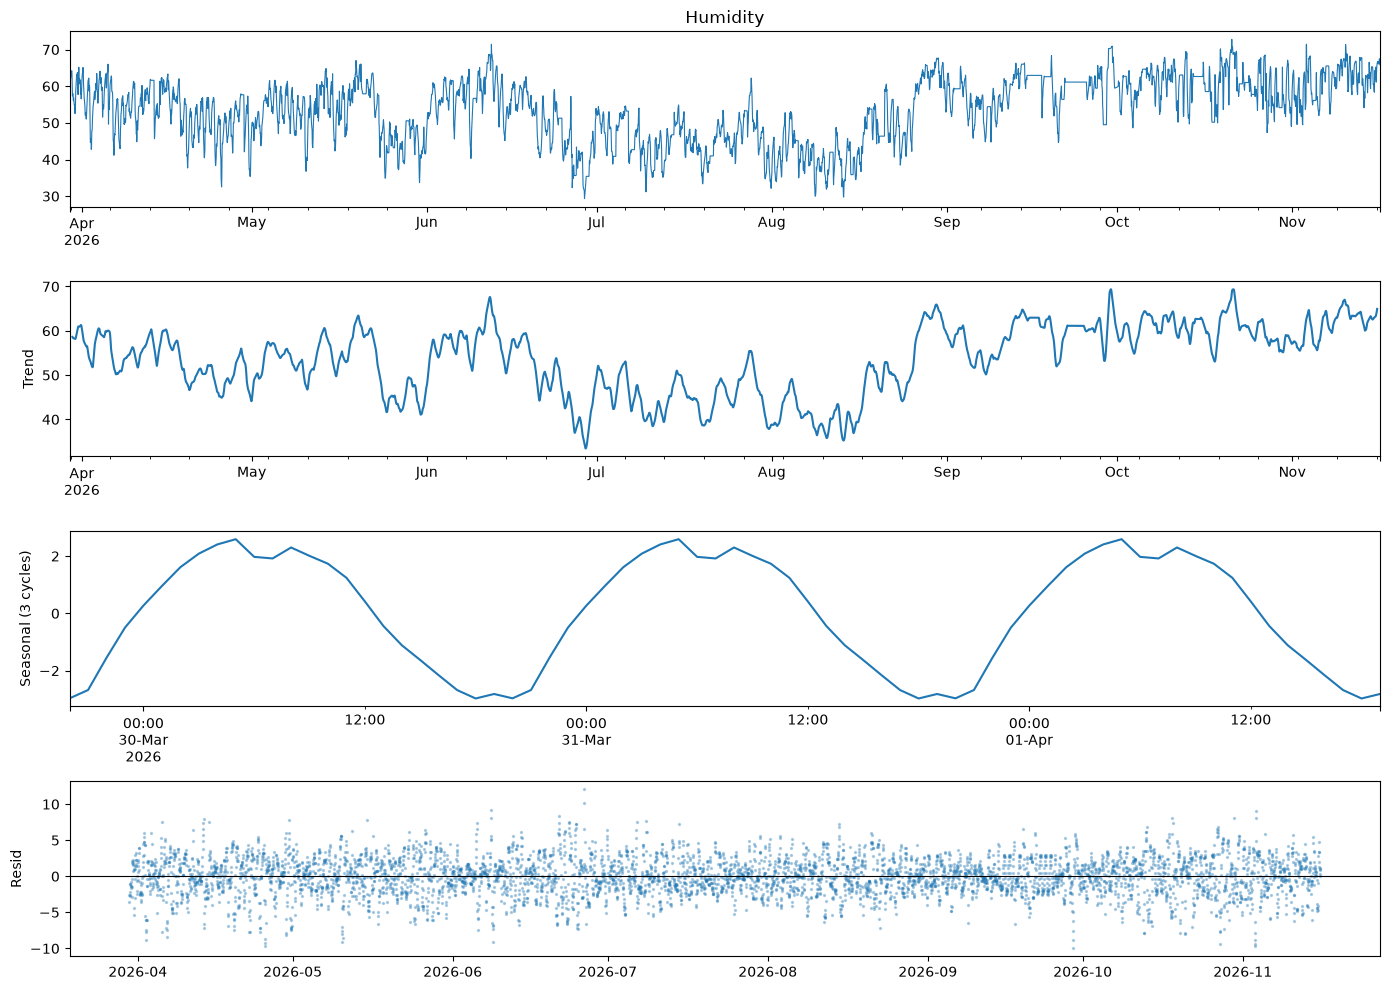

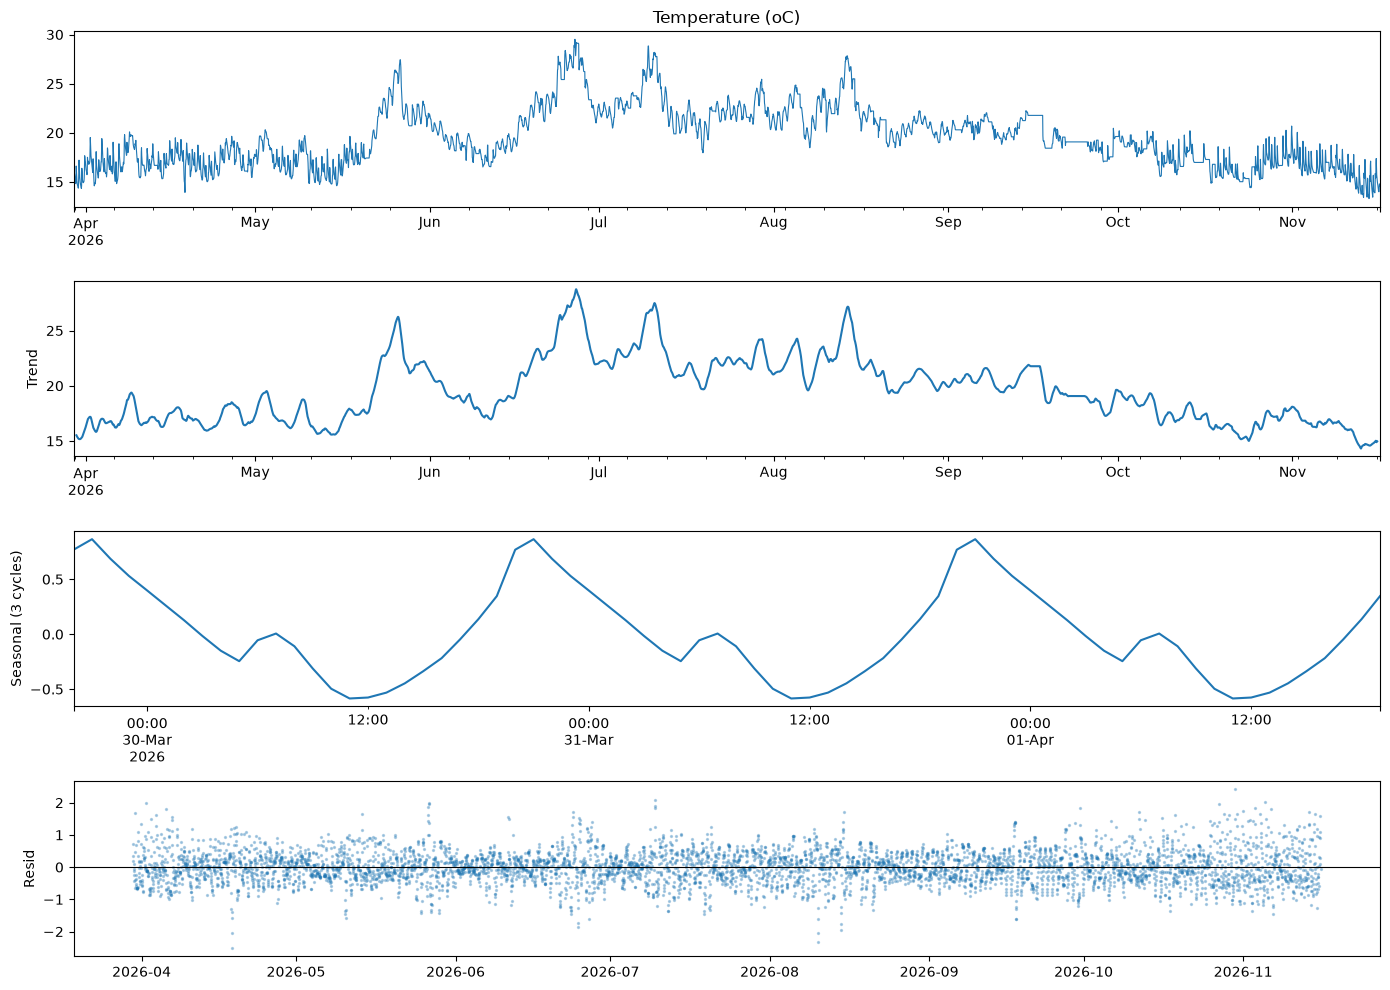

In [5]:
season_decomp(df=window_df,resample_size="1h")

### Modelling

* Naive and seasonal naive baselines
* Classical statistical model (ARIMA / SARIMA)
* Machine learning models (lag and rolling features)
* Model comparison and evaluation

### Results